# Gene Regulatory Network Inference Pipeline

This notebook orchestrates the entire GRN inference pipeline:
1. **Data Generation**: Generates a scale-free network and harvests time-series data pairs.
2. **Bayesian Inference**: Uses `graph-tool` and our custom `GeneExprBlockState` to run MCMC and infer the posterior ensemble of network topologies and parameters.
3. **Prediction**: Exports the ensemble to raw binaries and calls Julia to run high-performance stationary-state knockout simulations.

In [1]:
import numpy as np
import graph_tool.all as gt
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import seaborn as sns

# Add the parent directory to sys.path so we can import our modules and gene_expr


from inference_pipeline.data_generation.network_generator import generate_scale_free_W
from inference_pipeline.data_generation.simulator import simulate_realistic_pairs
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats
from inference_pipeline.inference.metrics import plot_probabilistic_network, plot_inferred_vs_true_am, compute_reconstruction_metrics
from inference_pipeline.prediction.export_utils import export_ensemble_to_bin, export_true_to_bin
from gene_expr import GeneExprBlockState

## 1. Data Generation

In [2]:
# Configuration
N = 10
m = 1
seed_network = 51

dt_sim = 0.005
dt_sample = 0.5
dt_meas = 0.5
M_pairs = 500
t_window = (0.0, 300.0)

mean_d = 0.5
mean_V = 0.1
D_base = 0.02

# Generate TRUE network
W_true = generate_scale_free_W(N, m, seed=seed_network)
theta_true = [np.log(mean_d), np.log(mean_V), np.log(D_base)]

# Simulate state-transition pairs
s, hub_node, out_degrees, d_true, V_true = simulate_realistic_pairs(
    W_true, M=M_pairs, dt_sim=dt_sim, dt_sample=dt_sample, dt_meas=dt_meas, 
    D_base=D_base, mean_d=mean_d, std_d=1, mean_V=mean_V, std_V=1, 
    seed=123, t_window=t_window
)

print(f"Harvested {len(s)} pairs. Master Regulator is Node {hub_node}.")

Harvested 500 pairs. Master Regulator is Node 0.


<Axes: >

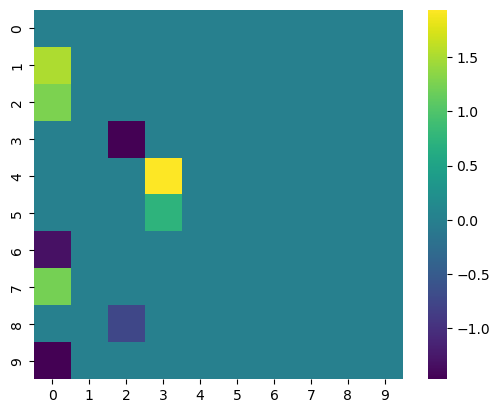

In [67]:
sns.heatmap(W_true, square=True, cmap='viridis', cbar=True)

In [68]:
s[0].shape

(10, 2)

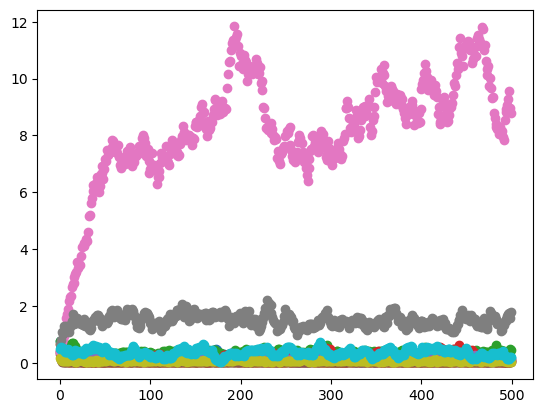

In [69]:
for j in range(N):
    plt.plot([s[i][j][0] for i in range(len(s))], 'o', label=f'Node {j}')


In [70]:
print(V_true)
print(d_true)

[0.05071816 0.09096376 0.44432657 0.05278717 0.0641477  0.06476847
 0.90786916 0.89065422 0.27293238 0.14713589]
[0.16884439 1.35553779 0.66353831 0.11086502 0.28034132 2.60723261
 0.04416483 0.32560841 1.77320577 0.2101597 ]


## 2. Bayesian Inference & MCMC

In [3]:
# Instantiate an empty graph in graph-tool format
g_init = gt.Graph(directed=True)
g_init.add_vertex(N)

# Add ~5% density of random edges to jump-start the MCMC and avoid the empty graph trap
num_initial_edges = max(1, int(N * N * 0.05))
possible_edges = [(u, v) for u in range(N) for v in range(N) if u != v]
np.random.shuffle(possible_edges)
for u, v in possible_edges[:num_initial_edges]:
    g_init.add_edge(u, v)

# Initialize the custom state with an uninformative prior
initial_theta = [0.0, 0.0, np.log(0.05)]
state = GeneExprBlockState(s, dt=dt_meas, g=g_init, state_args=dict(deg_corr=False), 
                           theta=initial_theta, use_em_likelihood=False, self_loop=False)
print(f"Initial description length (empty network): {state.entropy():.4f}")

# Phase 1: Burn-in
state = run_burn_in(state, n_burnin=50, theta_mode="local")

# Phase 2: Posterior Sampling
n_samples = 100
W_ensemble, theta_ensemble = run_posterior_sampling(state, N, n_samples=n_samples, delta_k=1, theta_mode="local")

# Compute and save ensemble stats
edge_probabilities, weight_mean, weight_std = compute_ensemble_stats(W_ensemble)

import os
os.makedirs("results", exist_ok=True)
np.savez_compressed(
    "results/grn_ensemble_results.npz", 
    W_ensemble=W_ensemble, 
    theta_ensemble=theta_ensemble,
    edge_probabilities=edge_probabilities,
    weight_mean=weight_mean,
    weight_std=weight_std
)
print("Ensemble results saved to results/grn_ensemble_results.npz!")

Initial description length (empty network): 16490.5846

--- PHASE 1: Equilibration (50 sweeps) ---
Burn-in Sweep  1/50: Entropy = -6310.1539 (dS_topo = -22800.7385, dS_param =  -0.0000, moves = 6136)


KeyboardInterrupt: 

### Inference Visualizations

In [85]:
V_true, d_true, theta_true

(array([0.05071816, 0.09096376, 0.44432657, 0.05278717, 0.0641477 ,
        0.06476847, 0.90786916, 0.89065422, 0.27293238, 0.14713589]),
 array([0.16884439, 1.35553779, 0.66353831, 0.11086502, 0.28034132,
        2.60723261, 0.04416483, 0.32560841, 1.77320577, 0.2101597 ]),
 [np.float64(-0.6931471805599453),
  np.float64(-2.3025850929940455),
  np.float64(-3.912023005428146)])

In [84]:
state.get_theta().get_2d_array()

array([[-1.38562777,  0.27636505, -0.32269793, -2.38435766, -0.64726589,
         1.14616005, -3.03304917, -0.98908437,  0.83386973, -1.68557257],
       [-2.69383175, -2.46442552, -0.97675079, -2.42350067, -2.13176844,
        -1.62730036, -0.19030849, -0.32771506, -1.19905669, -2.58309514],
       [-4.6287441 , -4.55393474, -4.60640211, -4.64230788, -4.52085269,
        -4.91390047, -4.85574764, -4.60174945, -4.37959895, -4.71249221]])

In [73]:
from sklearn.metrics import roc_auc_score, average_precision_score

print("\n--- Inference Metrics (Last Sample) ---")
metrics = compute_reconstruction_metrics(W_true, W_ensemble[-1])
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k}: {v:.4f}")
    else:
        print(f"{k}: {v}")

y_true = (W_true != 0).ravel().astype(int)
y_score = (edge_probabilities * np.abs(weight_mean)).ravel()

auroc = roc_auc_score(y_true, y_score)
auprc = average_precision_score(y_true, y_score)

print(f"AUROC: {auroc:.4f}")
print(f"AUPRC: {auprc:.4f}")
print("---------------------------------------\n")

plot_probabilistic_network(W_true, edge_probabilities * np.abs(weight_mean), save_path="images/probabilistic_network.png")
plot_inferred_vs_true_am(W_true, np.mean(W_ensemble, axis=0), save_path="images/am_comparison.png")


--- Inference Metrics (Last Sample) ---
TP: 3
FP: 10
FN: 6
TN: 71
TPR (Recall): 0.3333
FPR: 0.1235
Precision: 0.2308
F1-Score: 0.2727
SHD: 16
AUROC: 0.7466
AUPRC: 0.3072
---------------------------------------

Saved probabilistic network plot to images/probabilistic_network.png
Saved AM comparison plot to images/am_comparison.png


## 3. Julia Perturbation Analysis

In [ ]:
# Export numpy tensors to raw C-order binaries for fast Julia loading
export_ensemble_to_bin("results/grn_ensemble_results.npz", "results/W_ensemble.bin", "results/theta_ensemble.bin")
export_true_to_bin(W_true, theta_true, "results/W_true.bin", "results/theta_true.bin")

# Call the Julia script for knockout prediction and visualization
print(f"Running Julia simulation with Node {hub_node + 1}...")
subprocess.run(["julia", "prediction/predict_knockout.jl", str(hub_node + 1)], check=True)